[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/02_felicidad_mundial.ipynb)

# 😊 ¿Dónde se vive más feliz? Estadística descriptiva con el *World Happiness Report 2021*

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM**

Cada fila es un **país** (149). La variable estrella es el **Ladder score**: la puntuación media (0–10)
que dan los habitantes a la pregunta *"imagina una escalera donde 10 es la mejor vida posible y 0 la peor: ¿en qué peldaño estás?"*.

En este notebook vamos a responder preguntas como:
- ¿Cuál es el país "típico"? ¿Media o mediana?
- ¿Qué región del mundo es más feliz… y cuál es más **desigual**?
- ¿Hay países **anómalos**? (felices siendo pobres, o infelices siendo ricos)
- ¿Dónde está **España**?

> 💡 Ejecuta las celdas en orden (`Shift + Enter`). Donde veas **🤔**, para y piensa antes de seguir.

**Plan de trabajo (3 sesiones de 2 h):**
- 🕐 Sesión 1 · Describir una variable (apartados 1–5)
- 🕐 Sesión 2 · Atípicos y comparación de grupos (6–8)
- 🕐 Sesión 3 · Dos variables: correlación y regresión (9–11)

In [1]:
# ============================================================
# 0. Librerías y estilo de los gráficos
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if v != 0 and abs(v) < 0.01 else f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"

# Los datos están en el repositorio de GitHub: así no hay que subir nada a Colab
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

---
# 🕐 Sesión 1 de 3 · Describir una variable
**Objetivos:** tipos de variables, frecuencias, media/mediana/moda (incluida la moda interpolada), posición relativa, dispersión y forma.  
**Apartados:** 1 a 5 · **Duración orientativa:** 2 horas

## 1. Cargamos y miramos los datos
Antes de calcular nada: **¿cuántas filas, qué columnas, de qué tipo, hay huecos?**

In [2]:
df = pd.read_csv(URL_DATOS + "world-happiness-report-2021.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (149, 20)


,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.842,0.032,7.904,7.780,10.775,0.954,72.000,0.949,-0.098,0.186,2.430,1.446,1.106,0.741,0.691,0.124,0.481,3.253
1,Denmark,Western Europe,7.620,0.035,7.687,7.552,10.933,0.954,72.700,0.946,0.030,0.179,2.430,1.502,1.108,0.763,0.686,0.208,0.485,2.868
2,Switzerland,Western Europe,7.571,0.036,7.643,7.500,11.117,0.942,74.400,0.919,0.025,0.292,2.430,1.566,1.079,0.816,0.653,0.204,0.413,2.839
3,Iceland,Western Europe,7.554,0.059,7.670,7.438,10.878,0.983,73.000,0.955,0.160,0.673,2.430,1.482,1.172,0.772,0.698,0.293,0.170,2.967
4,Netherlands,Western Europe,7.464,0.027,7.518,7.410,10.932,0.942,72.400,0.913,0.175,0.338,2.430,1.501,1.079,0.753,0.647,0.302,0.384,2.798


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Country name                                149 non-null    str    
 1   Regional indicator                          149 non-null    str    
 2   Ladder score                                149 non-null    float64
 3   Standard error of ladder score              149 non-null    float64
 4   upperwhisker                                149 non-null    float64
 5   lowerwhisker                                149 non-null    float64
 6   Logged GDP per capita                       149 non-null    float64
 7   Social support                              149 non-null    float64
 8   Healthy life expectancy                     149 non-null    float64
 9   Freedom to make life choices                149 non-null    float64
 10  Generosity               

Las columnas `Explained by: ...`, `upperwhisker`, `lowerwhisker`, `Dystopia...` son resultados de un modelo de los autores.
Nos quedamos con las variables "en bruto" y les ponemos nombres cortos en castellano.

In [4]:
df = df.rename(columns={
    "Country name": "pais", "Regional indicator": "region", "Ladder score": "felicidad",
    "Logged GDP per capita": "log_PIB", "Social support": "apoyo_social",
    "Healthy life expectancy": "esperanza_vida", "Freedom to make life choices": "libertad",
    "Generosity": "generosidad", "Perceptions of corruption": "corrupcion",
})[["pais", "region", "felicidad", "log_PIB", "apoyo_social", "esperanza_vida",
    "libertad", "generosidad", "corrupcion"]]

# El PIB viene en logaritmo: recuperamos el PIB per cápita en dólares para ver la diferencia
df["PIB_pc"] = np.exp(df["log_PIB"])
cuantitativas = ["felicidad", "PIB_pc", "log_PIB", "apoyo_social", "esperanza_vida",
                 "libertad", "generosidad", "corrupcion"]
df.head()

,pais,region,felicidad,log_PIB,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,PIB_pc
0,Finland,Western Europe,7.842,10.775,0.954,72.000,0.949,-0.098,0.186,"47,810.473"
1,Denmark,Western Europe,7.620,10.933,0.954,72.700,0.946,0.030,0.179,"55,994.010"
2,Switzerland,Western Europe,7.571,11.117,0.942,74.400,0.919,0.025,0.292,"67,305.686"
3,Iceland,Western Europe,7.554,10.878,0.983,73.000,0.955,0.160,0.673,"52,997.499"
4,Netherlands,Western Europe,7.464,10.932,0.942,72.400,0.913,0.175,0.338,"55,938.044"


### Tipos de variables
| Variable | Tipo |
|---|---|
| `pais` | cualitativa nominal (identificador) |
| `region` | cualitativa nominal |
| `felicidad`, `PIB_pc`, `esperanza_vida`… | cuantitativas continuas |

🤔 *¿Tiene sentido calcular la "media" de `region`? ¿Y su moda?*

## 2. Variable cualitativa: tabla de frecuencias de `region`

In [5]:
frec = df["region"].value_counts().to_frame("n_i")
frec["f_i"] = frec["n_i"] / frec["n_i"].sum()
frec["N_i"] = frec["n_i"].cumsum()
frec["F_i"] = frec["f_i"].cumsum()
frec

,n_i,f_i,N_i,F_i
region,,,,
Sub-Saharan Africa,36,0.242,36,0.242
Western Europe,21,0.141,57,0.383
Latin America and Caribbean,20,0.134,77,0.517
Middle East and North Africa,17,0.114,94,0.631
Central and Eastern Europe,17,0.114,111,0.745
Commonwealth of Independent States,12,0.081,123,0.826
Southeast Asia,9,0.060,132,0.886
South Asia,7,0.047,139,0.933
East Asia,6,0.040,145,0.973


Las frecuencias acumuladas `N_i` y `F_i` aquí se pueden calcular… pero **no significan nada**,
porque las regiones no tienen un orden natural. Solo tienen sentido en variables **ordinales** o cuantitativas.

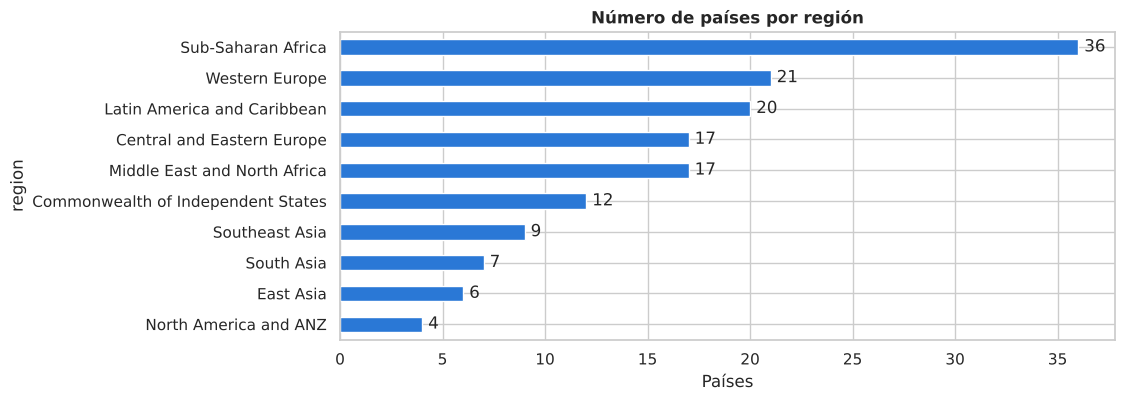

Moda de region: Sub-Saharan Africa


In [6]:
ax = df["region"].value_counts(ascending=True).plot.barh(color=AZUL)
ax.set_title("Número de países por región")
ax.set_xlabel("Países")
for i, v in enumerate(df["region"].value_counts(ascending=True)):
    ax.text(v + 0.3, i, str(v), va="center")
plt.show()
print("Moda de region:", df["region"].mode()[0])

## 3. Medidas de posición: ¿cuál es el país "típico"?

In [7]:
x = df["felicidad"]
print(f"Media              : {x.mean():.3f}")
print(f"Mediana            : {x.median():.3f}")
print(f"Moda (x.mode())    : {x.mode().tolist()[:5]} ...  ({x.mode().size} valores!)")
print(f"Media recortada 5% : {stats.trim_mean(x, 0.05):.3f}")

Media              : 5.533
Mediana            : 5.534
Moda (x.mode())    : [5.477, 5.929] ...  (2 valores!)
Media recortada 5% : 5.543


🤔 **¿Por qué `x.mode()` da dos valores raros?** En una variable continua casi ningún valor se repite: aquí solo
coinciden por casualidad dos parejas de países (Rusia y Hong Kong con 5.477; Argentina y Portugal con 5.929).
Eso no describe "el valor más habitual".

### La moda de una variable continua
Para continuas agrupamos en intervalos (aquí con Sturges: $k \approx 1 + 3{,}322\,\log_{10} n$), buscamos la **clase modal**
(la de mayor frecuencia) y, dentro de ella, **interpolamos**:
$$ Mo = L_i + \frac{d_1}{d_1 + d_2}\, a_i, \qquad d_1 = n_i - n_{i-1}, \quad d_2 = n_i - n_{i+1}$$
Geométricamente es el punto donde se **cortan las rectas que unen en cruz** las esquinas de la barra modal con las de sus vecinas.
Si la barra de la izquierda es más alta que la de la derecha, la moda se desplaza hacia la izquierda (y al revés).

Clase modal: [4.887, 5.478)  con n_i = 34  (izquierda: 21, derecha: 27)
d1 = 13,  d2 = 7  ->  Mo = 4.887 + 13/20 · 0.591 = 5.271


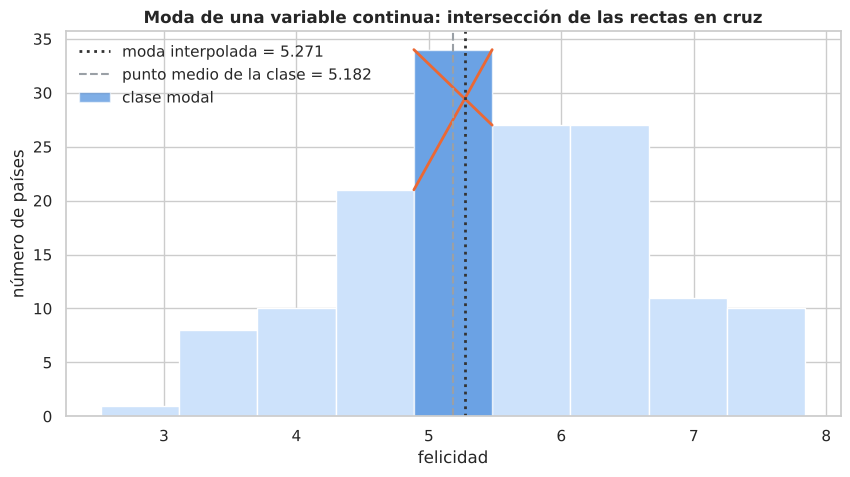

In [8]:
frec, bordes = np.histogram(x, bins="sturges")
i = frec.argmax()
L, a = bordes[i], bordes[i + 1] - bordes[i]          # extremo inferior y amplitud de la clase modal
n_izq, n_mod, n_der = frec[i - 1], frec[i], frec[i + 1]
d1, d2 = n_mod - n_izq, n_mod - n_der
Mo = L + d1 / (d1 + d2) * a
print(f"Clase modal: [{L:.3f}, {L + a:.3f})  con n_i = {n_mod}  (izquierda: {n_izq}, derecha: {n_der})")
print(f"d1 = {n_mod - n_izq},  d2 = {n_mod - n_der}  ->  Mo = {L:.3f} + {n_mod - n_izq}/{(n_mod - n_izq) + (n_mod - n_der)} · {a:.3f} = {Mo:.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(bordes[:-1], frec, width=np.diff(bordes), align="edge", color="#cde2fb", edgecolor="white")
ax.bar(L, n_mod, width=a, align="edge", color=AZUL, alpha=0.6, edgecolor="white", label="clase modal")
# Rectas en cruz dentro de la clase modal:
#   (L, n_mod) -> (L+a, n_der): esquina sup. izquierda de la modal con la altura de la vecina derecha
#   (L, n_izq) -> (L+a, n_mod): altura de la vecina izquierda con la esquina sup. derecha de la modal
ax.plot([L, L + a], [n_mod, n_der], color=NARANJA, lw=2)
ax.plot([L, L + a], [n_izq, n_mod], color=NARANJA, lw=2)
ax.axvline(Mo, color="#333333", ls=":", lw=2, label=f"moda interpolada = {Mo:.3f}")
ax.axvline(L + a / 2, color="#9aa0a6", ls="--", lw=1.5, label=f"punto medio de la clase = {L + a / 2:.3f}")
ax.set_title("Moda de una variable continua: intersección de las rectas en cruz")
ax.set_xlabel("felicidad"); ax.set_ylabel("número de países"); ax.legend(frameon=False, loc="upper left")
plt.show()

🤔 ¿Hacia qué lado se ha desplazado la moda respecto al punto medio de la clase? ¿Qué barra vecina "tira" más de ella?
Cambia `bins="sturges"` por `bins=6` o `bins=15`: **la moda de una continua depende de cómo agrupemos**.

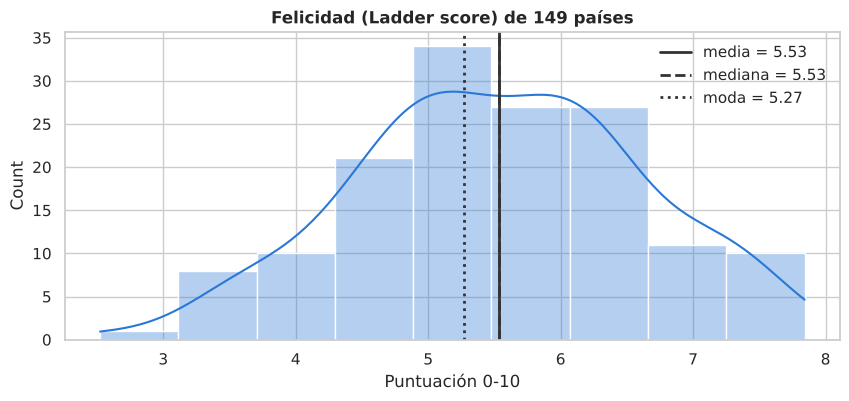

In [9]:
sns.histplot(x, bins="sturges", kde=True, color=AZUL, alpha=0.35)
plt.axvline(x.mean(), color="#333333", ls="-", lw=2, label=f"media = {x.mean():.2f}")
plt.axvline(x.median(), color="#333333", ls="--", lw=2, label=f"mediana = {x.median():.2f}")
plt.axvline(Mo, color="#333333", ls=":", lw=2, label=f"moda = {Mo:.2f}")
plt.title("Felicidad (Ladder score) de 149 países"); plt.xlabel("Puntuación 0-10"); plt.legend(frameon=False)
plt.show()

### Cuantiles, deciles y percentiles

In [10]:
print(df["felicidad"].quantile([0.10, 0.25, 0.50, 0.75, 0.90]).round(3))

0.100   4.223
0.250   4.852
0.500   5.534
0.750   6.255
0.900   7.072
Name: felicidad, dtype: float64


### ¿Y España? Posición relativa: percentil y puntuación tipificada (z)
$$ z = \frac{x - \bar x}{s} $$
z indica **a cuántas desviaciones típicas** de la media está un país. Sirve para comparar variables con unidades distintas.

In [11]:
pais = "Spain"          # 👈 cambia el país: "Finland", "Mexico", "Japan"...
fila = df[df["pais"] == pais].iloc[0]
print(pais)
for v in ["felicidad", "PIB_pc", "apoyo_social", "esperanza_vida", "libertad", "generosidad", "corrupcion"]:
    z = (fila[v] - df[v].mean()) / df[v].std()
    percentil = 100 * (df[v] <= fila[v]).mean()        # % de países con un valor menor o igual
    print(f"{v:15s} valor = {fila[v]:10.3f}   z = {z:+.2f}   percentil = {percentil:5.1f}")

Spain
felicidad       valor =      6.491   z = +0.89   percentil =  82.6
PIB_pc          valor =  38987.642   z = +0.83   percentil =  78.5
apoyo_social    valor =      0.932   z = +1.02   percentil =  84.6
esperanza_vida  valor =     74.700   z = +1.44   percentil =  98.0
libertad        valor =      0.761   z = -0.27   percentil =  37.6
generosidad     valor =     -0.081   z = -0.44   percentil =  38.3
corrupcion      valor =      0.745   z = +0.10   percentil =  41.6


🤔 España está en el percentil 98 de esperanza de vida… pero por debajo de la mitad en libertad percibida.
Cambia `pais` por tu país favorito y vuelve a ejecutar la celda.

## 4. Medidas de dispersión: ¿son los países parecidos entre sí?

In [12]:
x = df["felicidad"]
print(f"Rango                 : {x.max() - x.min():.3f}  ({df.loc[x.idxmin(), 'pais']} → {df.loc[x.idxmax(), 'pais']})")
print(f"IQR (rango intercuart.): {x.quantile(.75) - x.quantile(.25):.3f}")
print(f"Varianza  (n-1)       : {x.var():.3f}     | numpy por defecto (n): {np.var(x):.3f}")
print(f"Desv. típica (n-1)    : {x.std():.3f}     | numpy por defecto (n): {np.std(x):.3f}")
print(f"Coef. de variación    : {100 * x.std() / x.mean():.1f} %")
print(f"MAD                   : {stats.median_abs_deviation(x):.3f}")

Rango                 : 5.319  (Afghanistan → Finland)
IQR (rango intercuart.): 1.403
Varianza  (n-1)       : 1.153     | numpy por defecto (n): 1.146
Desv. típica (n-1)    : 1.074     | numpy por defecto (n): 1.070
Coef. de variación    : 19.4 %
MAD                   : 0.700


⚠️ **Trampa clásica:** `pandas` divide entre $n-1$ (cuasivarianza) y `numpy` entre $n$. Con 149 datos la diferencia es pequeña;
con 5 datos no. Mirad siempre qué fórmula usa la función.

### Coeficiente de variación: comparar dispersión de variables con unidades distintas
¿Qué varía más entre países: el **PIB** (dólares) o la **esperanza de vida** (años)? Comparar desviaciones típicas no tiene sentido; el CV sí.

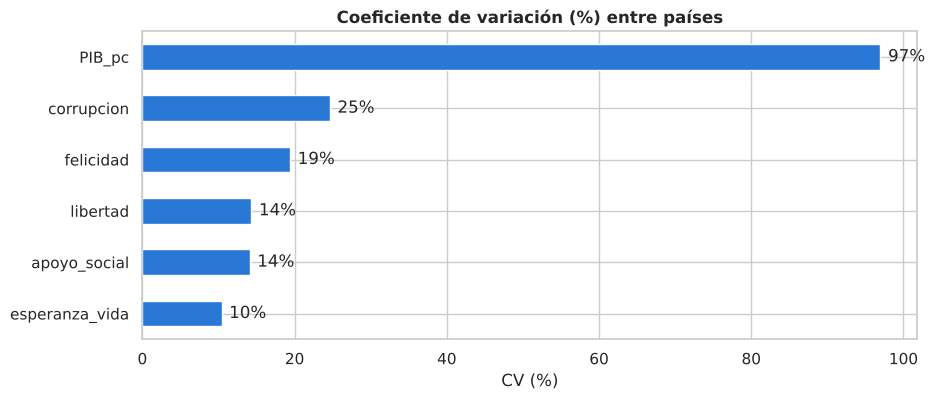

In [13]:
cv = (100 * df[cuantitativas].std() / df[cuantitativas].mean().abs()).drop(["generosidad", "log_PIB"]).sort_values()
ax = cv.plot.barh(color=AZUL)
ax.set_title("Coeficiente de variación (%) entre países"); ax.set_xlabel("CV (%)")
for i, v in enumerate(cv): ax.text(v + 1, i, f"{v:.0f}%", va="center")
plt.show()

🤔 `generosidad` la hemos quitado: su media es casi 0 (es un residuo, puede ser negativa). **¿Qué le pasa al CV cuando la media se acerca a 0?**

## 5. Medidas de forma: asimetría y curtosis
- Asimetría > 0 → cola a la **derecha**, normalmente media > mediana.
- Asimetría < 0 → cola a la **izquierda**, normalmente media < mediana.
- Curtosis (exceso) > 0 → colas más pesadas que la normal.

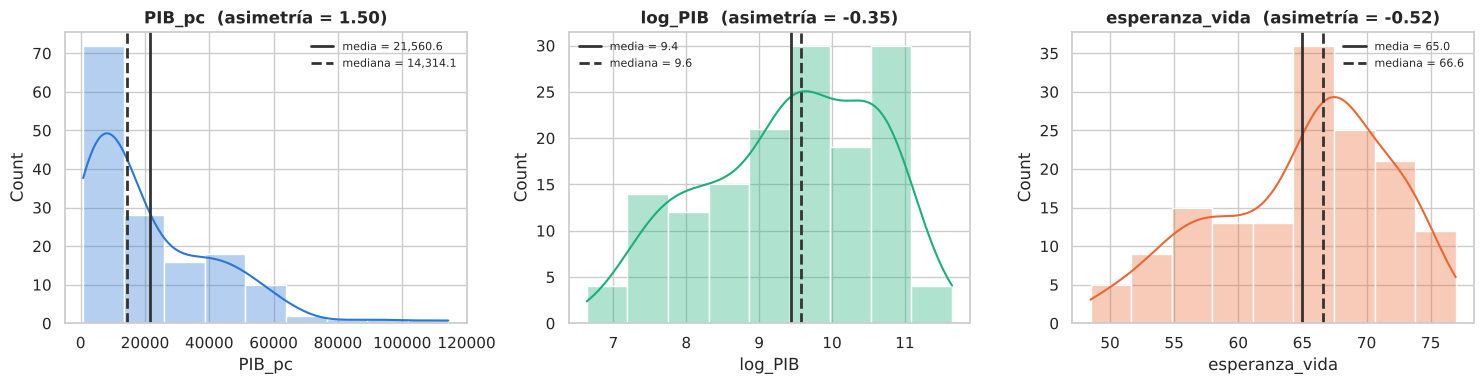

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, v, col in zip(axes, ["PIB_pc", "log_PIB", "esperanza_vida"], [AZUL, VERDE, NARANJA]):
    sns.histplot(df[v], bins="sturges", kde=True, color=col, alpha=0.35, ax=ax)
    ax.axvline(df[v].mean(), color="#333333", ls="-", lw=2, label=f"media = {df[v].mean():,.1f}")
    ax.axvline(df[v].median(), color="#333333", ls="--", lw=2, label=f"mediana = {df[v].median():,.1f}")
    ax.set_title(f"{v}  (asimetría = {df[v].skew():.2f})"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

🎯 **Fijaos en el truco del logaritmo:** el PIB per cápita es muy asimétrico a la derecha (pocos países muy ricos);
al tomar logaritmos la distribución se vuelve casi simétrica. Por eso los economistas trabajan con `log_PIB`.

### 🚀 Retos de la sesión 1
1. Ejecuta la ficha de país con tres países que elijas. ¿En qué variable destaca cada uno (mayor |z|)?
2. Repite el cálculo de la moda interpolada de `felicidad` con `np.histogram(x, bins=6)` y con `bins=15`. ¿Cuánto cambia respecto a Sturges?
3. ¿Qué variable es más asimétrica: `generosidad` o `corrupcion`? Dibuja sus histogramas con la media y la mediana marcadas y comprueba si se separan como esperas.

---
✅ **Fin de la sesión 1.**

---
# 🕐 Sesión 2 de 3 · Atípicos y comparación de grupos
**Objetivos:** tabla resumen completa, atípicos (Tukey y residuos), comparación de regiones con `groupby`, perfiles tipificados.  
**Apartados:** 6 a 8 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 6. Tabla resumen de TODAS las variables cuantitativas

In [15]:
tabla = df[cuantitativas].agg(["count", "mean", "median", "min", "max", "var", "std", "skew", "kurt"]).T
tabla["Q1"] = df[cuantitativas].quantile(0.25)
tabla["Q3"] = df[cuantitativas].quantile(0.75)
tabla["rango"] = tabla["max"] - tabla["min"]
tabla["IQR"] = tabla["Q3"] - tabla["Q1"]
tabla["CV_%"] = 100 * tabla["std"] / tabla["mean"].abs()
tabla.style.format("{:,.2f}").background_gradient(subset=["skew"], cmap="RdBu_r", vmin=-2, vmax=2)

,count,mean,median,min,max,var,std,skew,kurt,Q1,Q3,rango,IQR,CV_%
felicidad,149.00,5.53,5.53,2.52,7.84,1.15,1.07,-0.10,-0.37,4.85,6.25,5.32,1.40,19.41
PIB_pc,149.00,"21,560.61","14,314.10",761.28,"114,347.80","437,177,275.79","20,908.78",1.50,2.74,"5,120.46","33,556.97","113,586.53","28,436.51",96.98
log_PIB,149.00,9.43,9.57,6.63,11.65,1.34,1.16,-0.35,-0.82,8.54,10.42,5.01,1.88,12.28
apoyo_social,149.00,0.81,0.83,0.46,0.98,0.01,0.11,-0.94,0.39,0.75,0.91,0.52,0.16,14.10
esperanza_vida,149.00,64.99,66.60,48.48,76.95,45.73,6.76,-0.52,-0.56,59.80,69.60,28.48,9.80,10.40
libertad,149.00,0.79,0.80,0.38,0.97,0.01,0.11,-0.75,0.41,0.72,0.88,0.59,0.16,14.32
generosidad,149.00,-0.02,-0.04,-0.29,0.54,0.02,0.15,1.01,1.64,-0.13,0.08,0.83,0.21,995.47
corrupcion,149.00,0.73,0.78,0.08,0.94,0.03,0.18,-1.58,2.25,0.67,0.84,0.86,0.18,24.64


## 7. Datos anómalos (atípicos)
**Regla de Tukey** (la del diagrama de caja): es atípico todo lo que esté fuera de
$[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$.

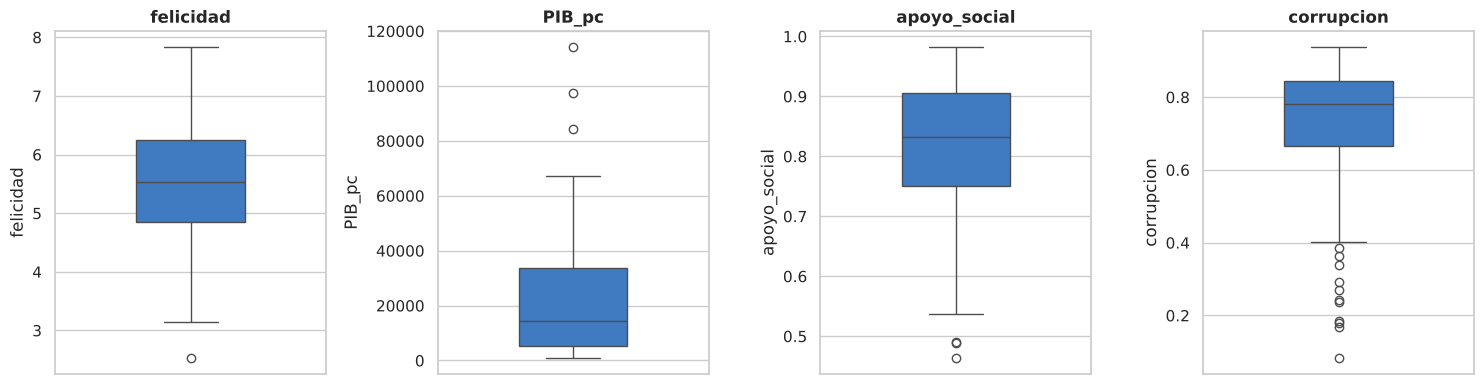

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, v in zip(axes, ["felicidad", "PIB_pc", "apoyo_social", "corrupcion"]):
    sns.boxplot(y=df[v], ax=ax, color=AZUL, width=0.4, fliersize=6)
    ax.set_title(v)
plt.tight_layout(); plt.show()

In [17]:
for v in ["felicidad", "apoyo_social", "corrupcion", "esperanza_vida"]:
    q1, q3 = df[v].quantile(0.25), df[v].quantile(0.75)
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    at = df.loc[(df[v] < li) | (df[v] > ls), ["pais", "region", v]]
    print(f"\n--- {v}: vallas [{li:.2f}, {ls:.2f}] -> {len(at)} atípicos")
    print(at.to_string(index=False))


--- felicidad: vallas [2.75, 8.36] -> 1 atípicos
       pais     region  felicidad
Afghanistan South Asia      2.523

--- apoyo_social: vallas [0.52, 1.14] -> 3 atípicos
       pais             region  apoyo_social
      Benin Sub-Saharan Africa         0.489
    Burundi Sub-Saharan Africa         0.490
Afghanistan         South Asia         0.463

--- corrupcion: vallas [0.40, 1.11] -> 11 atípicos
       pais                region  corrupcion
    Finland        Western Europe       0.186
    Denmark        Western Europe       0.179
Switzerland        Western Europe       0.292
Netherlands        Western Europe       0.338
     Norway        Western Europe       0.270
     Sweden        Western Europe       0.237
 Luxembourg        Western Europe       0.386
New Zealand North America and ANZ       0.242
    Ireland        Western Europe       0.363
  Singapore        Southeast Asia       0.082
     Rwanda    Sub-Saharan Africa       0.167

--- esperanza_vida: vallas [45.11, 84.30] ->

🤔 Mirad `corrupcion`: los "atípicos" son los países nórdicos, Singapur… ¡con **muy poca** corrupción percibida!
Lo raro en el mundo es no tener corrupción.

Un atípico **no es un error**: Afganistán es realmente el país menos feliz del informe.
¿Qué haríais con él si quisierais describir a "un país típico"? ¿Lo quitaríais?

### Atípicos "relacionales": felicidad que no cuadra con la riqueza
Ajustamos una recta felicidad ~ log_PIB y miramos los países que más se alejan (residuos).

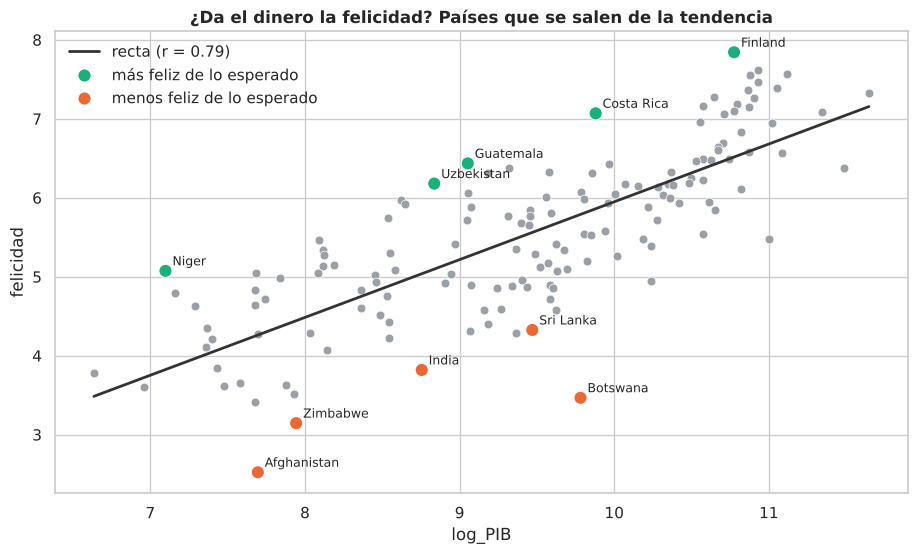

In [18]:
pend, ord_, r, *_ = stats.linregress(df["log_PIB"], df["felicidad"])
df["residuo"] = df["felicidad"] - (ord_ + pend * df["log_PIB"])

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=df, x="log_PIB", y="felicidad", color="#9aa0a6", s=40, ax=ax)
xs = np.linspace(df["log_PIB"].min(), df["log_PIB"].max(), 50)
ax.plot(xs, ord_ + pend * xs, color="#333333", lw=2, label=f"recta (r = {r:.2f})")
extremos = pd.concat([df.nlargest(5, "residuo"), df.nsmallest(5, "residuo")])
sns.scatterplot(data=extremos, x="log_PIB", y="felicidad", hue=np.where(extremos["residuo"] > 0, "más feliz de lo esperado", "menos feliz de lo esperado"),
                palette=[VERDE, NARANJA], s=90, ax=ax)
for _, f in extremos.iterrows():
    ax.annotate(f["pais"], (f["log_PIB"], f["felicidad"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_title("¿Da el dinero la felicidad? Países que se salen de la tendencia")
ax.legend(frameon=False); plt.show()

## 8. 🏆 Comparación por grupos con `groupby`: ¿qué región es más feliz… y más desigual?

In [19]:
por_region = (df.groupby("region")["felicidad"]
                .agg(n="size", media="mean", mediana="median", desv="std",
                     minimo="min", maximo="max",
                     IQR=lambda s: s.quantile(.75) - s.quantile(.25))
                .assign(CV=lambda t: 100 * t["desv"] / t["media"])
                .sort_values("mediana", ascending=False))
por_region.style.format("{:.2f}").background_gradient(subset=["mediana"], cmap="Blues").background_gradient(subset=["CV"], cmap="Oranges")

,n,media,mediana,desv,minimo,maximo,IQR,CV
region,,,,,,,,
North America and ANZ,4.00,7.13,7.14,0.14,6.95,7.28,0.14,1.94
Western Europe,21.00,6.91,7.08,0.66,5.54,7.84,0.90,9.49
Central and Eastern Europe,17.00,5.98,6.08,0.49,5.10,6.96,0.44,8.24
Latin America and Caribbean,20.00,5.91,5.99,0.69,3.62,7.07,0.56,11.74
East Asia,6.00,5.81,5.76,0.44,5.34,6.58,0.39,7.57
Commonwealth of Independent States,12.00,5.47,5.47,0.44,4.88,6.18,0.60,8.01
Southeast Asia,9.00,5.41,5.38,0.61,4.43,6.38,0.85,11.21
South Asia,7.00,4.44,4.93,0.99,2.52,5.27,1.04,22.37
Middle East and North Africa,17.00,5.22,4.89,1.00,3.66,7.16,1.52,19.14


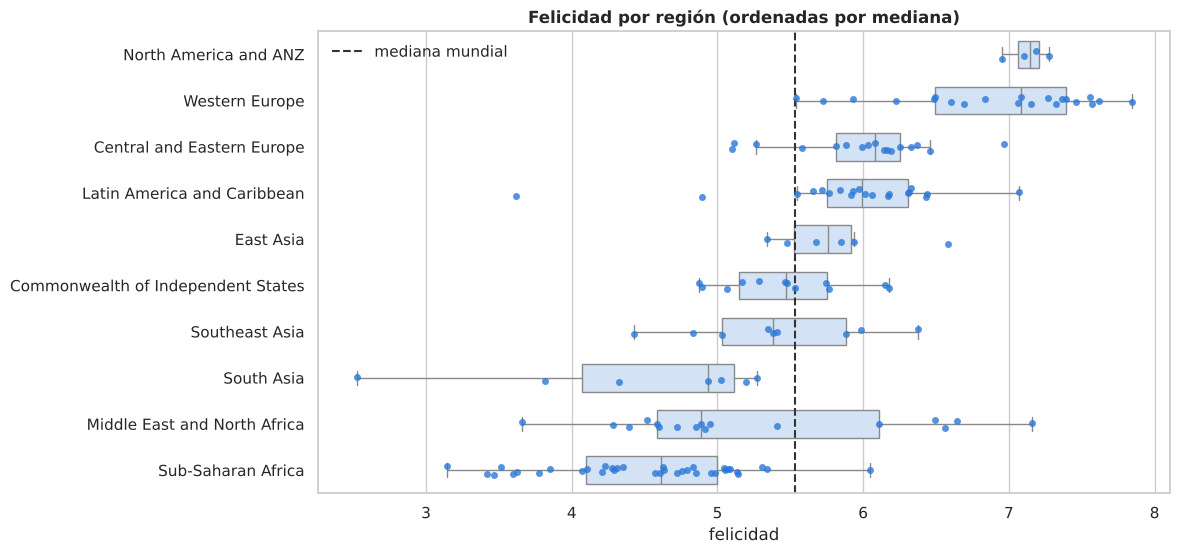

In [20]:
orden = por_region.index
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=df, y="region", x="felicidad", order=orden, color="#cde2fb", width=0.6, fliersize=0, ax=ax)
sns.stripplot(data=df, y="region", x="felicidad", order=orden, color=AZUL, size=5, alpha=0.8, ax=ax)
ax.axvline(df["felicidad"].median(), color="#333333", ls="--", lw=1.5, label="mediana mundial")
ax.set_title("Felicidad por región (ordenadas por mediana)"); ax.set_ylabel(""); ax.legend(frameon=False)
plt.show()

🤔 **Preguntas:**
1. ¿Qué región tiene la **mayor dispersión**? ¿Y la menor? (mira `IQR` y `CV`)
2. "North America and ANZ" solo tiene **4 países**. ¿Te fiarías de su media para compararla con África (36 países)?
3. ¿En qué región la media y la mediana se separan más? ¿Por qué?

### Perfil de cada región en todas las variables (tipificadas)
Tipificamos cada variable (z) para poder ponerlas en la misma escala y pintamos un mapa de calor.

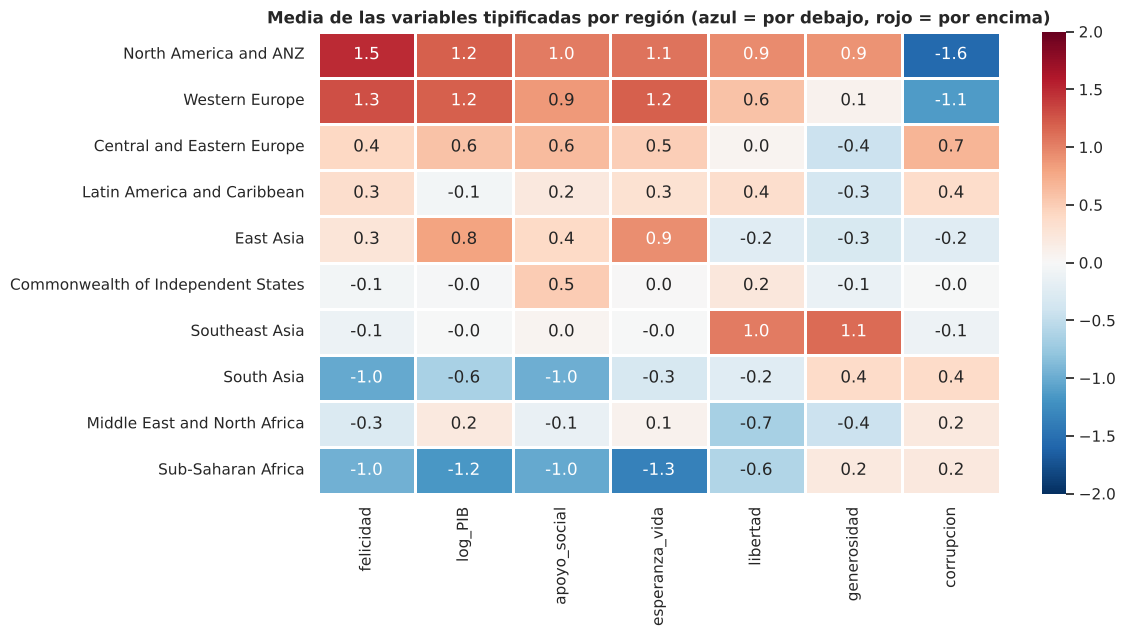

In [21]:
vars_perfil = ["felicidad", "log_PIB", "apoyo_social", "esperanza_vida", "libertad", "generosidad", "corrupcion"]
z = (df[vars_perfil] - df[vars_perfil].mean()) / df[vars_perfil].std()
perfil = z.groupby(df["region"]).mean().loc[orden]
plt.figure(figsize=(11, 6))
sns.heatmap(perfil, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, linewidths=2, linecolor="white")
plt.title("Media de las variables tipificadas por región (azul = por debajo, rojo = por encima)")
plt.ylabel(""); plt.show()

### ⚠️ La media de los países NO es la media del mundo
Hemos tratado igual a India (1.400 millones) que a Islandia (370.000). La media de esta tabla es la del
"país típico", **no la de la persona típica**. Para eso necesitaríamos una **media ponderada** por población.

### 🚀 Retos de la sesión 2
1. Calcula media, mediana, desviación típica, IQR y asimetría de `esperanza_vida` **por región** con `df.groupby("region")["esperanza_vida"].agg([...])`.
2. Crea una variable cualitativa ordinal `nivel_felicidad` con `pd.cut` (baja / media / alta) y haz una tabla de contingencia con `region` (`pd.crosstab(..., normalize="index")`).
3. ¿Qué país europeo es el más "anómalo" según su residuo? ¿Y el latinoamericano?
4. Repite el análisis de atípicos con z-scores ( |z| > 2.5 ). ¿Salen los mismos países que con Tukey?

---
✅ **Fin de la sesión 2.**

---
# 🕐 Sesión 3 de 3 · Dos variables: correlación y regresión
**Objetivos:** covarianza y correlación, regresión lineal, potencial y exponencial, elasticidad, residuos, regla empírica y Chebyshev.  
**Apartados:** 9 a 11 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 9. Dos variables a la vez: covarianza y correlación

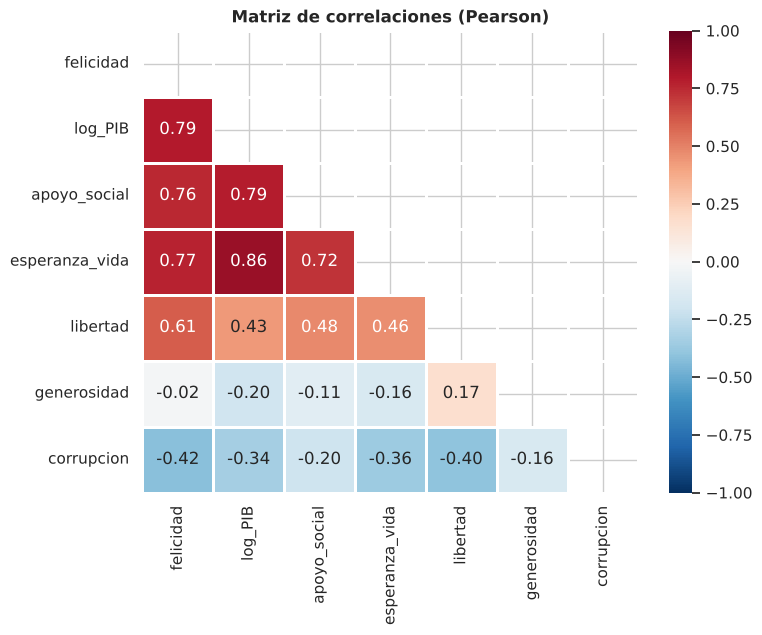

In [22]:
corr = df[vars_perfil].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=2, linecolor="white")
plt.title("Matriz de correlaciones (Pearson)"); plt.show()

In [23]:
print("Covarianza felicidad–esperanza_vida :", round(df["felicidad"].cov(df["esperanza_vida"]), 3))
print("Covarianza felicidad–log_PIB         :", round(df["felicidad"].cov(df["log_PIB"]), 3))
print("Correlación felicidad–esperanza_vida :", round(df["felicidad"].corr(df["esperanza_vida"]), 3))
print("Correlación felicidad–log_PIB        :", round(df["felicidad"].corr(df["log_PIB"]), 3))

Covarianza felicidad–esperanza_vida : 5.578
Covarianza felicidad–log_PIB         : 0.983
Correlación felicidad–esperanza_vida : 0.768
Correlación felicidad–log_PIB        : 0.79


🤔 La covarianza con esperanza de vida es mucho mayor que con log_PIB, pero la correlación es menor. **¿Por qué?**
(pista: unidades). Y recordad: **correlación no implica causalidad**.

## 10. 📈 Regresión: ¿cuántos años de vida "compra" el dinero?
Explicamos la **esperanza de vida saludable** ($y$) a partir del **PIB per cápita** ($x$, en dólares) con tres modelos:

| Modelo | Ecuación | Linealización |
|---|---|---|
| Lineal | $y = a + b\,x$ | — |
| Potencial | $y = a\,x^{b}$ | $\ln y = \ln a + b\,\ln x$ |
| Exponencial | $y = a\,e^{b x}$ | $\ln y = \ln a + b\,x$ |

Con $b = S_{xy}/S_x^2$ y $a = \bar y - b\,\bar x$ aplicados a los datos originales o transformados.

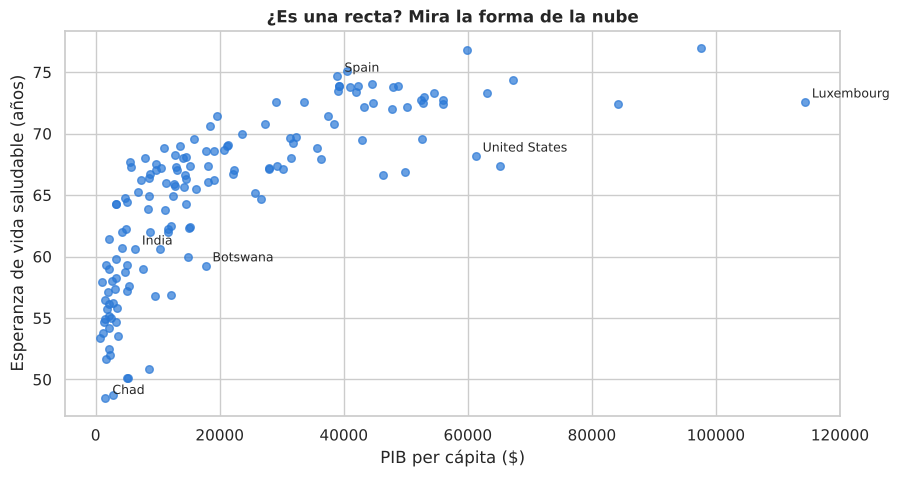

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df["PIB_pc"], df["esperanza_vida"], color=AZUL, s=30, alpha=0.7)
for p in ["Spain", "United States", "Luxembourg", "India", "Chad", "Botswana"]:
    f = df.loc[df["pais"] == p].iloc[0]
    ax.annotate(p, (f["PIB_pc"], f["esperanza_vida"]), xytext=(5, 3), textcoords="offset points", fontsize=9)
ax.set_xlabel("PIB per cápita ($)"); ax.set_ylabel("Esperanza de vida saludable (años)")
ax.set_title("¿Es una recta? Mira la forma de la nube")
plt.show()

🤔 La nube **no es recta**: sube muy deprisa en los países pobres y se aplana en los ricos (rendimientos decrecientes).
Es la famosa **curva de Preston** (1975). Veamos qué transformación la endereza:

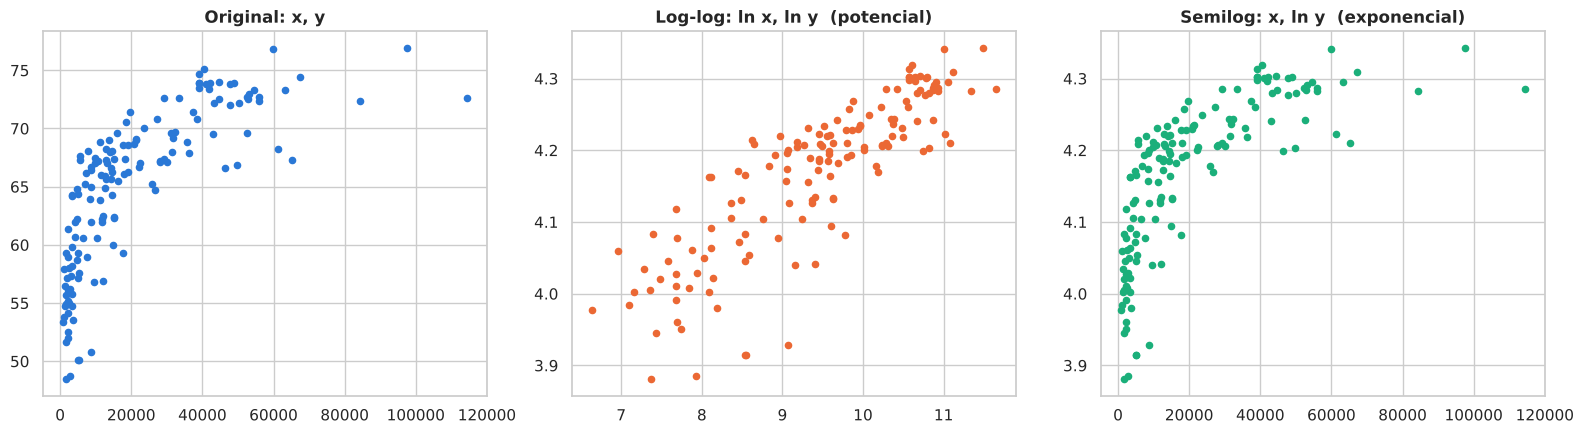

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(df["PIB_pc"], df["esperanza_vida"], s=20, color=AZUL); axes[0].set_title("Original: x, y")
axes[1].scatter(np.log(df["PIB_pc"]), np.log(df["esperanza_vida"]), s=20, color=NARANJA); axes[1].set_title("Log-log: ln x, ln y  (potencial)")
axes[2].scatter(df["PIB_pc"], np.log(df["esperanza_vida"]), s=20, color=VERDE); axes[2].set_title("Semilog: x, ln y  (exponencial)")
for a_ in axes: a_.set_xlabel(""); 
plt.tight_layout(); plt.show()

In [26]:
x, y = df["PIB_pc"], df["esperanza_vida"]
lx, ly = np.log(x), np.log(y)

# --- Lineal: y = a + b·x
b_lin = ((x - x.mean()) * (y - y.mean())).mean() / ((x - x.mean()) ** 2).mean()
a_lin = y.mean() - b_lin * x.mean()
pred_lin = a_lin + b_lin * x

# --- Potencial: ln y = ln a + b·ln x
b_pot = ((lx - lx.mean()) * (ly - ly.mean())).mean() / ((lx - lx.mean()) ** 2).mean()
a_pot = np.exp(ly.mean() - b_pot * lx.mean())
pred_pot = a_pot * x ** b_pot

# --- Exponencial: ln y = ln a + b·x
b_exp = ((x - x.mean()) * (ly - ly.mean())).mean() / ((x - x.mean()) ** 2).mean()
a_exp = np.exp(ly.mean() - b_exp * x.mean())
pred_exp = a_exp * np.exp(b_exp * x)

# --- R² en la escala original
SC_total = ((y - y.mean()) ** 2).sum()
print(f"Lineal      : y = {a_lin:.3f} + {b_lin:.3e}·x        R² = {1 - ((y - pred_lin) ** 2).sum() / SC_total:.3f}")
print(f"Potencial   : y = {a_pot:.3f}·x^{b_pot:.4f}          R² = {1 - ((y - pred_pot) ** 2).sum() / SC_total:.3f}")
print(f"Exponencial : y = {a_exp:.3f}·e^({b_exp:.3e}·x)   R² = {1 - ((y - pred_exp) ** 2).sum() / SC_total:.3f}")

Lineal      : y = 59.857 + 2.382e-04·x        R² = 0.542
Potencial   : y = 30.586·x^0.0793          R² = 0.737
Exponencial : y = 59.679·e^(3.694e-06·x)   R² = 0.502


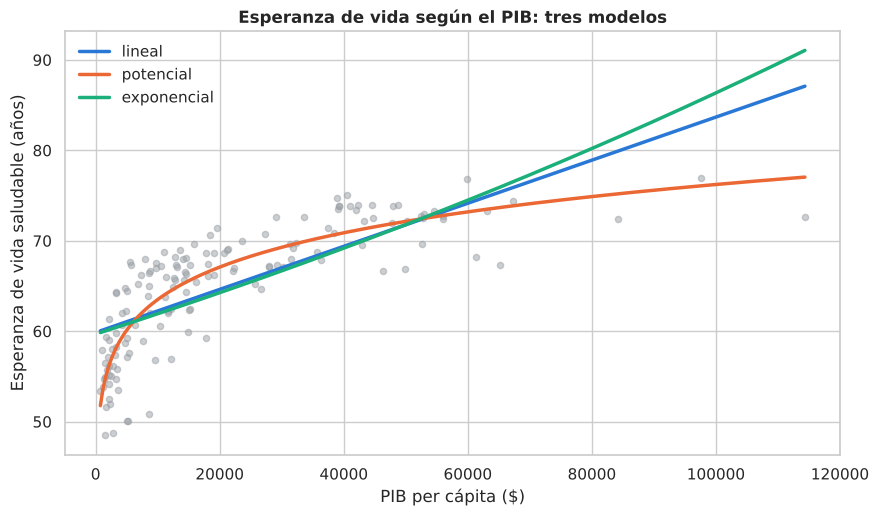

In [27]:
xs = np.linspace(x.min(), x.max(), 300)
plt.figure(figsize=(10, 5.5))
plt.scatter(x, y, s=20, alpha=0.5, color="#9aa0a6")
plt.plot(xs, a_lin + b_lin * xs, color=AZUL, lw=2.5, label="lineal")
plt.plot(xs, a_pot * xs ** b_pot, color=NARANJA, lw=2.5, label="potencial")
plt.plot(xs, a_exp * np.exp(b_exp * xs), color=VERDE, lw=2.5, label="exponencial")
plt.xlabel("PIB per cápita ($)"); plt.ylabel("Esperanza de vida saludable (años)")
plt.title("Esperanza de vida según el PIB: tres modelos"); plt.legend(frameon=False)
plt.show()

🎯 **Gana el modelo potencial** con claridad. El exponente $b$ es pequeño (≈ 0,08): es una **elasticidad**.
Si el PIB se multiplica por 2, la esperanza de vida se multiplica por $2^{b}$. Calcúlalo:

In [28]:
print(f"Duplicar el PIB multiplica la esperanza de vida por 2^{b_pot:.4f} = {2**b_pot:.4f}  (+{100*(2**b_pot - 1):.1f} %)")
for pib in [2000, 4000, 30000, 60000]:
    print(f"PIB {pib:>6,} $ -> esperanza de vida (potencial) {a_pot * pib ** b_pot:.1f} años")

Duplicar el PIB multiplica la esperanza de vida por 2^0.0793 = 1.0565  (+5.7 %)
PIB  2,000 $ -> esperanza de vida (potencial) 55.9 años
PIB  4,000 $ -> esperanza de vida (potencial) 59.0 años
PIB 30,000 $ -> esperanza de vida (potencial) 69.3 años
PIB 60,000 $ -> esperanza de vida (potencial) 73.2 años


🤔 Pasar de 2.000 a 4.000 $ "da" muchos más años que pasar de 30.000 a 60.000 $, aunque en ambos casos el PIB se duplica.
Y el modelo exponencial (que supone que **cada dólar** añade el mismo porcentaje) es **peor que la recta**.

### Residuos: ¿quién vive más (o menos) de lo que "le toca" por su PIB?

In [29]:
df["residuo_vida"] = df["esperanza_vida"] - a_pot * df["PIB_pc"] ** b_pot
extremos_vida = pd.concat([df.nlargest(5, "residuo_vida"), df.nsmallest(5, "residuo_vida")])
extremos_vida[["pais", "region", "PIB_pc", "esperanza_vida", "residuo_vida"]].round(1)

,pais,region,PIB_pc,esperanza_vida,residuo_vida
54,Nicaragua,Latin America and Caribbean,"5,541.400",67.700,7.100
58,Honduras,Latin America and Caribbean,"5,698.700",67.300,6.600
77,Tajikistan,Commonwealth of Independent States,"3,265.000",64.300,6.200
86,Nepal,South Asia,"3,361.000",64.200,6.000
78,Vietnam,Southeast Asia,"7,887.200",68.000,5.700
129,Swaziland,Sub-Saharan Africa,"8,647.300",50.800,-11.900
84,Ivory Coast,Sub-Saharan Africa,"5,171.900",50.100,-10.200
115,Nigeria,Sub-Saharan Africa,"5,079.700",50.100,-10.100
144,Lesotho,Sub-Saharan Africa,"2,768.300",48.700,-8.600
102,South Africa,Sub-Saharan Africa,"12,124.700",56.900,-7.600


In [30]:
fila = df.loc[df["pais"] == "Spain"].iloc[0]
print(f"España: PIB {fila['PIB_pc']:,.0f} $ -> el modelo predice {a_pot * fila['PIB_pc'] ** b_pot:.1f} años; "
      f"tiene {fila['esperanza_vida']:.1f} (residuo {fila['residuo_vida']:+.1f})")

España: PIB 38,988 $ -> el modelo predice 70.7 años; tiene 74.7 (residuo +4.0)


### ¿Y la felicidad?

Repetimos los mismos pasos con la felicidad como $y$. Esta vez calculamos **dos** $R^2$ para los modelos con logaritmos:
el de la recta ajustada a $\ln y$ (**escala del ajuste**) y el de las predicciones de $y$ (**escala original**).

Lineal      : R² = 0.556
Potencial   : R² escala del ajuste (ln y) = 0.601 | R² escala original = 0.635
Exponencial : R² escala del ajuste (ln y) = 0.493 | R² escala original = 0.482


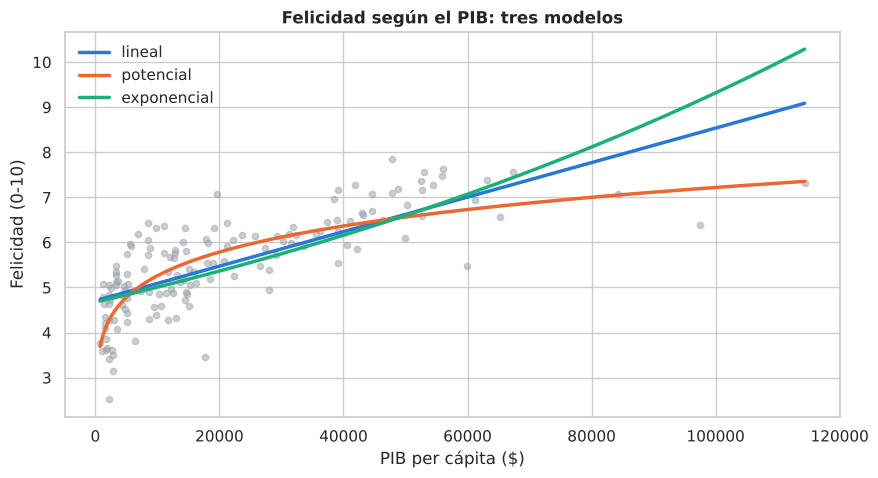

In [31]:
x, y = df["PIB_pc"], df["felicidad"]
lx, ly = np.log(x), np.log(y)

b_lin = ((x - x.mean()) * (y - y.mean())).mean() / ((x - x.mean()) ** 2).mean()
a_lin = y.mean() - b_lin * x.mean()
b_pot = ((lx - lx.mean()) * (ly - ly.mean())).mean() / ((lx - lx.mean()) ** 2).mean()
A_pot = ly.mean() - b_pot * lx.mean()
b_exp = ((x - x.mean()) * (ly - ly.mean())).mean() / ((x - x.mean()) ** 2).mean()
A_exp = ly.mean() - b_exp * x.mean()

SC_total = ((y - y.mean()) ** 2).sum()
SC_total_log = ((ly - ly.mean()) ** 2).sum()
r2_lin = 1 - ((y - (a_lin + b_lin * x)) ** 2).sum() / SC_total
r2_pot_log = 1 - ((ly - (A_pot + b_pot * lx)) ** 2).sum() / SC_total_log
r2_pot = 1 - ((y - np.exp(A_pot) * x ** b_pot) ** 2).sum() / SC_total
r2_exp_log = 1 - ((ly - (A_exp + b_exp * x)) ** 2).sum() / SC_total_log
r2_exp = 1 - ((y - np.exp(A_exp) * np.exp(b_exp * x)) ** 2).sum() / SC_total
print(f"Lineal      : R² = {r2_lin:.3f}")
print(f"Potencial   : R² escala del ajuste (ln y) = {r2_pot_log:.3f} | R² escala original = {r2_pot:.3f}")
print(f"Exponencial : R² escala del ajuste (ln y) = {r2_exp_log:.3f} | R² escala original = {r2_exp:.3f}")

xs = np.linspace(x.min(), x.max(), 300)
plt.figure(figsize=(10, 5))
plt.scatter(x, y, s=20, alpha=0.5, color="#9aa0a6")
plt.plot(xs, a_lin + b_lin * xs, color=AZUL, lw=2.5, label="lineal")
plt.plot(xs, np.exp(A_pot) * xs ** b_pot, color=NARANJA, lw=2.5, label="potencial")
plt.plot(xs, np.exp(A_exp) * np.exp(b_exp * xs), color=VERDE, lw=2.5, label="exponencial")
plt.xlabel("PIB per cápita ($)"); plt.ylabel("Felicidad (0-10)"); plt.title("Felicidad según el PIB: tres modelos")
plt.legend(frameon=False); plt.show()

⚠️ **Cuidado al comparar los $R^2$.** El de la **escala del ajuste** mide qué tal se ajusta la recta a los logaritmos;
el de la **escala original**, cuánto se acercan las predicciones a los datos de verdad. Para elegir modelo hay que usar
el de la escala original: el otro mide errores en "logaritmos de puntos de felicidad", no en puntos.

## 11. ¿Se parece a una normal? Regla empírica vs. desigualdad de Chebyshev
- Normal: ~68 % de datos en $\bar x \pm s$, ~95 % en $\bar x \pm 2s$, ~99.7 % en $\bar x \pm 3s$.
- Chebyshev (vale para **cualquier** distribución): al menos $1 - 1/k^2$ en $\bar x \pm ks$.

In [32]:
for v in ["felicidad", "PIB_pc"]:
    m, s = df[v].mean(), df[v].std()
    print(f"\n{v}:   (normal: 68.3 / 95.4 / 99.7 %   ·   Chebyshev: al menos 0 / 75 / 88.9 %)")
    for k in [1, 2, 3]:
        dentro = df[v].between(m - k * s, m + k * s).mean()
        print(f"  dentro de media ± {k}·s: {100 * dentro:.1f} %")


felicidad:   (normal: 68.3 / 95.4 / 99.7 %   ·   Chebyshev: al menos 0 / 75 / 88.9 %)
  dentro de media ± 1·s: 69.1 %
  dentro de media ± 2·s: 98.0 %
  dentro de media ± 3·s: 100.0 %

PIB_pc:   (normal: 68.3 / 95.4 / 99.7 %   ·   Chebyshev: al menos 0 / 75 / 88.9 %)
  dentro de media ± 1·s: 83.2 %
  dentro de media ± 2·s: 96.6 %
  dentro de media ± 3·s: 98.0 %


### 🚀 Retos de la sesión 3
1. Ajusta los tres modelos para `felicidad` frente a `apoyo_social`. ¿Cuál gana? ¿Tiene sentido el exponente?
2. Repite la regresión esperanza de vida ~ PIB **solo para África subsahariana** y **solo para Europa occidental**. ¿Sigue ganando el potencial? ¿Por qué?
3. ¿Qué país tiene la esperanza de vida más alta **respecto a lo que predice su PIB** dentro de Europa?

---
🏁 **Fin del notebook.**